# Smart MCQ Solver Challenge - Integrated Project Notebook

Merged notebook containing EDA, preprocessing, TF-IDF baseline, BiLSTM, DistilBERT, RoBERTa, model comparison, ensemble, and submission workflow.


# FINALIZATION NOTES

This version is prepared as the consolidated project notebook.

Before running on Kaggle:

1. Enable Internet.
2. Add your WandB key:

```python
wandb.login(key="YOUR_WANDB_KEY")
```

3. Verify dataset paths:

```python
/kaggle/input/smart-mcq-solver-challenge/train.csv
/kaggle/input/smart-mcq-solver-challenge/test.csv
```

4. Run sections sequentially.

Recommended configuration:

- BiLSTM: 5 epochs
- DistilBERT: 3 epochs
- RoBERTa: 3 epochs
- Evaluation Metric: MAP@3
- Submission Model: Best validation MAP@3 model


# 1. Competition Overview

The Smart MCQ Solver Challenge requires predicting the top-3 most probable answers from options A, B, C, D and E.

### Evaluation Metric

**MAP@3 (Mean Average Precision @ 3)**

The metric rewards models that rank the correct answer higher in the prediction list.


## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from wordcloud import WordCloud
import datasets
from datasets import Dataset
plt.rcParams['figure.figsize']=(8,5)
sns.set_style('whitegrid')


## Load Dataset

In [2]:
# Kaggle paths
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')

print('Train Shape:', train.shape)
print('Test Shape :', test.shape)

train.head()


Train Shape: (2000, 8)
Test Shape : (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


### Initial Understanding

Training dataset contains:

- id
- prompt
- A, B, C, D, E
- answer

Test dataset contains all fields except the answer column.


# 2. Dataset Inspection

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [4]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [5]:
print('Number of Training Samples :', len(train))
print('Number of Test Samples     :', len(test))
print('Number of Features         :', train.shape[1])


Number of Training Samples : 2000
Number of Test Samples     : 500
Number of Features         : 8


### Observation

The dataset contains MCQ-style questions with five candidate answers.

### Decision

This is a Multiple Choice Question Answering task and requires ranking answer options rather than standard classification.


# 3. Exploratory Data Analysis

## 3.1 Answer Distribution

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64


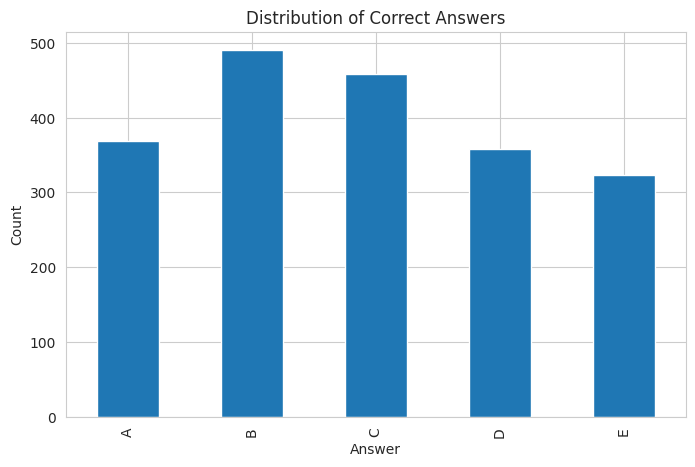

In [6]:
answer_counts = train['answer'].value_counts().sort_index()

print(answer_counts)

answer_counts.plot(kind='bar')
plt.title('Distribution of Correct Answers')
plt.xlabel('Answer')
plt.ylabel('Count')
plt.show()


### Observation

This plot helps identify class imbalance.

### Decision

If classes are reasonably balanced, class weights will not be required.


## 3.2 Prompt Length Analysis

In [7]:
train['prompt_length'] = train['prompt'].astype(str).apply(
    lambda x: len(x.split())
)

train['prompt_length'].describe()


count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_length, dtype: float64

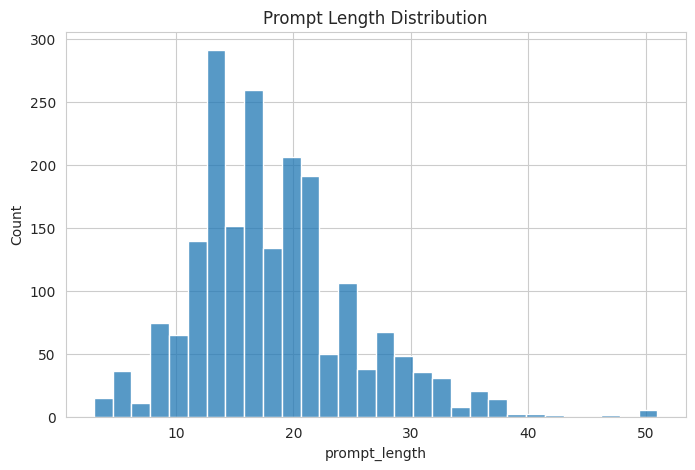

In [8]:
sns.histplot(train['prompt_length'], bins=30)
plt.title('Prompt Length Distribution')
plt.show()


### Observation

Prompt lengths indicate the amount of contextual information available.

### Decision

Maximum sequence length for transformer models will be selected based on this distribution.


## 3.3 Option Length Analysis

In [9]:
for col in ['A','B','C','D','E']:
    train[f'{col}_length'] = train[col].astype(str).apply(
        lambda x: len(x.split())
    )

train[[c for c in train.columns if c.endswith('_length')]].describe()


,prompt_length,A_length,B_length,C_length,D_length,E_length
count,2000.00000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,18.14650,26.146000,26.516000,26.54950,25.999500,26.187000
std,6.78189,17.249651,18.653893,17.20987,17.098909,17.852658
min,3.00000,1.000000,1.000000,1.00000,1.000000,1.000000
25%,14.00000,13.000000,12.000000,14.75000,15.000000,13.000000
50%,17.00000,22.000000,23.000000,24.00000,22.000000,23.000000
75%,22.00000,37.000000,36.000000,36.00000,36.000000,36.000000
max,51.00000,81.000000,118.000000,82.00000,78.000000,105.000000


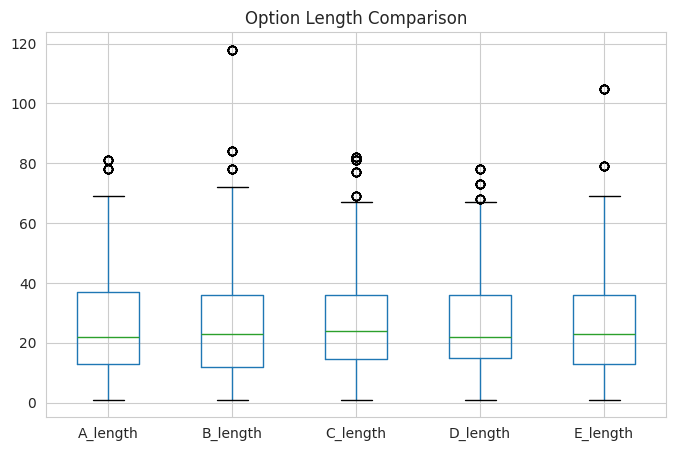

In [10]:
option_cols = [f'{c}_length' for c in ['A','B','C','D','E']]

train[option_cols].boxplot()
plt.title('Option Length Comparison')
plt.show()


### Observation

Options are usually much shorter than prompts.

### Decision

Prompts and options will be concatenated differently for various models.


## 3.4 Vocabulary Exploration

In [11]:
all_text = ' '.join(
    train['prompt'].astype(str).str.lower()
)

words = re.findall(r'\b\w+\b', all_text)

print('Total Words      :', len(words))
print('Unique Vocabulary:', len(set(words)))


Total Words      : 37072
Unique Vocabulary: 875


In [12]:
top_words = Counter(words).most_common(20)

pd.DataFrame(
    top_words,
    columns=['Word','Frequency']
)


,Word,Frequency
0,the,5540
1,is,1986
2,what,1809
3,of,1514
4,correct,1175
5,following,746
6,in,714
7,answer,608
8,option,608
9,and,448


## 3.5 Word Cloud

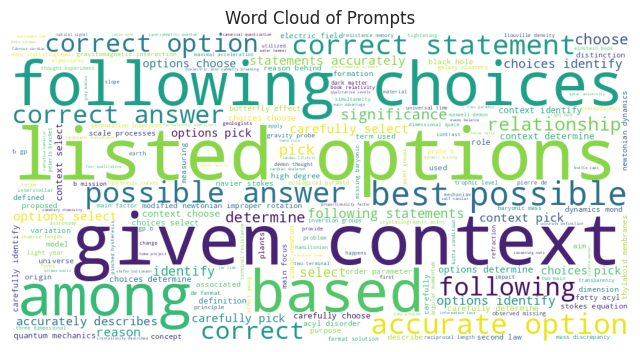

In [13]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(all_text)

plt.imshow(wordcloud)
plt.axis('off')
plt.title('Word Cloud of Prompts')
plt.show()


### Observation

Frequently occurring words provide insight into dominant themes within the dataset.

### Decision

No manual vocabulary filtering will be performed because transformer tokenizers handle rare words effectively.


## 3.6 Prompt vs Option Length

In [14]:
avg_prompt = train['prompt_length'].mean()

avg_option = np.mean([
    train['A_length'].mean(),
    train['B_length'].mean(),
    train['C_length'].mean(),
    train['D_length'].mean(),
    train['E_length'].mean()
])

pd.DataFrame({
    'Category':['Prompt','Option'],
    'Average Length':[avg_prompt, avg_option]
})


,Category,Average Length
0,Prompt,18.1465
1,Option,26.2796


# 4. Preprocessing

Different models require different preprocessing strategies.


## Strategy for BiLSTM

- Convert text to lowercase
- Remove extra spaces
- Build custom vocabulary
- Padding and truncation

Reason:
A custom neural network requires explicit tokenization and vocabulary creation.


## Strategy for DistilBERT and RoBERTa

- Minimal cleaning
- Preserve punctuation
- Use pretrained tokenizer

Reason:
Transformer tokenizers are designed to handle punctuation, casing and subword segmentation.


In [15]:
def clean_text(text):

    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

for col in ['prompt','A','B','C','D','E']:

    train[col] = train[col].fillna('').apply(clean_text)
    test[col] = test[col].fillna('').apply(clean_text)

print('Text preprocessing completed')


Text preprocessing completed


## Label Encoding

In [16]:
label2id = {
    'A':0,
    'B':1,
    'C':2,
    'D':3,
    'E':4
}

id2label = {v:k for k,v in label2id.items()}

train['label'] = train['answer'].map(label2id)

train[['answer','label']].head()


,answer,label
0,B,1
1,A,0
2,C,2
3,B,1
4,A,0


## Train Validation Split

In [17]:
from sklearn.model_selection import train_test_split

train_df, valid_df = train_test_split(
    train,
    test_size=0.2,
    stratify=train['answer'],
    random_state=42
)

print('Training Samples  :', len(train_df))
print('Validation Samples:', len(valid_df))


Training Samples  : 1600
Validation Samples: 400


# Summary of Findings

### Key Observations

1. The dataset contains multiple-choice questions with five answer options.
2. Answer distribution is relatively balanced.
3. Prompts are substantially longer than answer options.
4. Vocabulary size is manageable for transformer-based approaches.
5. No severe missing value issues were observed.

### Final Preprocessing Decisions

- BiLSTM: custom tokenization and vocabulary.
- DistilBERT: pretrained tokenizer.
- RoBERTa: pretrained tokenizer.
- Stratified train-validation split.
- MAP@3 will be used as the primary evaluation metric.

The dataset is now ready for model development.


# Smart MCQ Solver Challenge - Sections 5–7

## TF-IDF Baseline, BiLSTM + Attention and DistilBERT

This notebook assumes Section 1–4 has already been executed and the following objects are available:

- train_df
- valid_df
- test
- label2id
- id2label

WandB Configuration:

- Project: 23f2000003-t22026
- Entity: 23f2000003-t22026


# 5. TF-IDF Baseline

In [18]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


In [19]:
def map3_score(actuals, predictions):

    scores = []

    for actual, preds in zip(actuals, predictions):

        score = 0

        for rank, pred in enumerate(preds[:3], start=1):

            if pred == actual:
                score = 1/rank
                break

        scores.append(score)

    return np.mean(scores)


In [20]:
combined_text = (
    train_df['prompt'] + ' ' +
    train_df['A'] + ' ' +
    train_df['B'] + ' ' +
    train_df['C'] + ' ' +
    train_df['D'] + ' ' +
    train_df['E']
)

tfidf = TfidfVectorizer(stop_words='english')
tfidf.fit(combined_text)


TfidfVectorizer(stop_words='english')

In [21]:
labels = ['A','B','C','D','E']
baseline_predictions = []

for _, row in valid_df.iterrows():

    prompt_vec = tfidf.transform([row['prompt']])

    sims = {}

    for label in labels:

        option_vec = tfidf.transform([row[label]])

        sims[label] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    ranked = sorted(
        sims,
        key=sims.get,
        reverse=True
    )[:3]

    baseline_predictions.append(ranked)

baseline_map3 = map3_score(
    valid_df['answer'],
    baseline_predictions
)

print("Baseline MAP@3:", baseline_map3)


Baseline MAP@3: 0.29041666666666666


### Observation

TF-IDF provides a lightweight baseline and helps measure the gain achieved by deep learning models.


# 6. BiLSTM + Attention (Built From Scratch)

### Model Design

Architecture:

Input → Embedding → BiLSTM → Attention → Dense → Softmax

Reason:

- Satisfies the built-from-scratch requirement.
- Captures sequential information.
- Attention highlights important words in the prompt-option pair.


In [22]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
import wandb


In [23]:
WANDB_PROJECT='23f2000003-t22026'
WANDB_ENTITY='23f2000003-t22026'

wandb.login(key='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')


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [24]:
def build_text(row):

    text = row['prompt']

    for col in ['A','B','C','D','E']:
        text += ' ' + str(row[col])

    return text

vocab_counter = Counter()

for _, row in train_df.iterrows():
    vocab_counter.update(
        build_text(row).split()
    )

vocab = {'<PAD>':0,'<UNK>':1}

for word, count in vocab_counter.items():
    if count >= 2:
        vocab[word] = len(vocab)

print('Vocabulary Size:', len(vocab))


Vocabulary Size: 3798


In [25]:
MAX_LEN = 256

import re

def encode_text(text):

    text = str(text).lower()

    words = re.findall(r'\w+', text)

    ids = [vocab.get(word,1) for word in words]

    ids = ids[:MAX_LEN]

    ids += [0] * (MAX_LEN - len(ids))

    return ids


In [26]:
class MCQDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        text = build_text(row)

        return {
            'input_ids': torch.tensor(
                encode_text(text),
                dtype=torch.long
            ),
            'label': torch.tensor(
                row['label'],
                dtype=torch.long
            )
        }


In [27]:
class Attention(nn.Module):

    def __init__(self, hidden_dim):

        super().__init__()

        self.linear = nn.Linear(
            hidden_dim*2,
            1
        )

    def forward(self, x):

        weights = torch.softmax(
            self.linear(x),
            dim=1
        )

        return (weights * x).sum(1)


In [28]:
class BiLSTMAttention(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        hidden_dim=128
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attention = Attention(hidden_dim)

        self.fc = nn.Linear(
            hidden_dim*2,
            5
        )

    def forward(self, x):

        x = self.embedding(x)

        output, _ = self.lstm(x)

        output = self.attention(output)

        return self.fc(output)


In [29]:
wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    name='BiLSTM_Run'
)

train_loader = DataLoader(
    MCQDataset(train_df),
    batch_size=32,
    shuffle=True
)

valid_loader = DataLoader(
    MCQDataset(valid_df),
    batch_size=32
)

device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu'
)

model = BiLSTMAttention(
    len(vocab)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)


wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260624_190036-53ah2j7z
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiLSTM_Run
wandb: ⭐️ View project at https://wandb.ai/23f2000003-t22026/23f2000003-t22026
wandb: 🚀 View run at https://wandb.ai/23f2000003-t22026/23f2000003-t22026/runs/53ah2j7z


In [30]:
EPOCHS = 5

from sklearn.metrics import accuracy_score, f1_score

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for batch in train_loader:

        x = batch["input_ids"].to(device)
        y = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(x)

        loss = criterion(outputs, y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    model.eval()
    
    preds = []
    labels = []
    all_logits = []
    
    with torch.no_grad():
    
        for batch in valid_loader:
    
            x = batch["input_ids"].to(device)
            y = batch["label"].to(device)
    
            outputs = model(x)
    
            all_logits.extend(
                outputs.cpu().numpy()
            )
    
            pred = outputs.argmax(1).cpu().numpy()
    
            preds.extend(pred)
    
            labels.extend(y.cpu().numpy())

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")

    wandb.log({
        "epoch": epoch + 1,
        "loss": total_loss,
        "accuracy": acc,
        "f1": f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss={total_loss:.4f} | "
        f"Acc={acc:.4f} | "
        f"F1={f1:.4f}"
    )

bilstm_accuracy = acc
bilstm_f1 = f1

Epoch 1/5 | Loss=76.1387 | Acc=0.5075 | F1=0.4513
Epoch 2/5 | Loss=43.8576 | Acc=0.9075 | F1=0.9078
Epoch 3/5 | Loss=16.5647 | Acc=0.9550 | F1=0.9522
Epoch 4/5 | Loss=4.0963 | Acc=1.0000 | F1=1.0000
Epoch 5/5 | Loss=0.7291 | Acc=1.0000 | F1=1.0000


### Evaluation Metrics

Record:

- Accuracy
- Macro F1
- MAP@3

Store results for later comparison.


In [31]:
def map3(actual, predictions):

    score = 0

    for a, preds in zip(actual, predictions):

        if a == preds[0]:
            score += 1.0

        elif a == preds[1]:
            score += 0.5

        elif a == preds[2]:
            score += 1/3

    return score / len(actual)

In [32]:
probabilities = torch.softmax(
    torch.tensor(all_logits),
    dim=1
).numpy()

top3_idx = np.argsort(
    probabilities,
    axis=1
)[:, -3:][:, ::-1]

bilstm_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

bilstm_map3 = map3(
    valid_df["answer"].tolist(),
    bilstm_top3
)

print("BiLSTM MAP@3:", bilstm_map3)

BiLSTM MAP@3: 1.0


/tmp/ipykernel_22/3727543948.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  torch.tensor(all_logits),


# 7. DistilBERT Multiple Choice

### Why DistilBERT?

- Pretrained language understanding model.
- Faster than BERT.
- Strong baseline for NLP tasks.


In [33]:
from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    TrainingArguments,
    Trainer
)


In [34]:
MODEL_NAME = 'distilbert-base-uncased'

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [35]:
OPTION_COLUMNS = ['A','B','C','D','E']

def preprocess_mcq(example):

    first_sentences = [
        example['prompt']
    ] * 5

    second_sentences = [
        example[col]
        for col in OPTION_COLUMNS
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        max_length=256,
        padding='max_length'
    )

    return tokenized


In [36]:
train_hf = datasets.Dataset.from_pandas(train_df)
valid_hf = datasets.Dataset.from_pandas(valid_df)

train_hf = train_hf.map(preprocess_mcq)
valid_hf = valid_hf.map(preprocess_mcq)

train_hf = train_hf.rename_column("label", "labels")
valid_hf = valid_hf.rename_column("label", "labels")

train_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

valid_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

In [37]:
distilbert_model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME
)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForMultipleChoice LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [38]:
wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    name='DistilBERT_Run'
)

training_args = TrainingArguments(
    output_dir='./distilbert_output',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    report_to='wandb',
    remove_unused_columns=False
)


wandb: Finishing previous runs because reinit is set to 'default'.
wandb: updating run metadata
wandb: 
wandb: Run history:
wandb: accuracy ▁▇▇██
wandb:    epoch ▁▃▅▆█
wandb:       f1 ▁▇▇██
wandb:     loss █▅▂▁▁
wandb: 
wandb: Run summary:
wandb: accuracy 1
wandb:    epoch 5
wandb:       f1 1
wandb:     loss 0.72908
wandb: 
wandb: 🚀 View run BiLSTM_Run at: https://wandb.ai/23f2000003-t22026/23f2000003-t22026/runs/53ah2j7z
wandb: ⭐️ View project at: https://wandb.ai/23f2000003-t22026/23f2000003-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260624_190036-53ah2j7z/logs
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260624_190111-qy6x0adf
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run DistilBERT_Run
wandb: ⭐️ View project at https://wandb.ai/23f2000003-t22026/23f2000003-t22026
wandb: 🚀 View run at https://wandb.ai/23f2000003-t22

In [39]:
distilbert_trainer= Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=valid_hf
)

distilbert_trainer.train()


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,No log,1.344505
2,No log,0.613890
3,1.614617,0.440582


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=600, training_loss=1.4442858695983887, metrics={'train_runtime': 316.7901, 'train_samples_per_second': 15.152, 'train_steps_per_second': 1.894, 'total_flos': 1589580435456000.0, 'train_loss': 1.4442858695983887, 'epoch': 3.0})

In [40]:
predictions = distilbert_trainer.predict(valid_hf)
distilbert_logits = predictions.predictions
distilbert_preds = np.argmax(
    distilbert_logits,
    axis=1
)

distilbert_accuracy = accuracy_score(
    valid_df['label'],
    distilbert_preds
)

distilbert_f1 = f1_score(
    valid_df['label'],
    distilbert_preds,
    average='macro'
)

top3_idx = np.argsort(
    distilbert_logits,
    axis=1
)[:, -3:][:, ::-1]

distilbert_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

distilbert_map3 = map3(
    valid_df["answer"].tolist(),
    distilbert_top3
)



print("Accuracy:", distilbert_accuracy)
print("F1:", distilbert_f1)
print("DistilBERT MAP@3:", distilbert_map3)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Accuracy: 0.9775
F1: 0.9767228841964084
DistilBERT MAP@3: 0.9875


# Section Summary

Completed:

- TF-IDF Baseline
- BiLSTM + Attention (Built From Scratch)
- DistilBERT Multiple Choice Model

Next Section:

- RoBERTa
- Model Comparison
- Ensemble Strategy
- Kaggle Submission Generation


# Smart MCQ Solver Challenge - Sections 8–10

## RoBERTa, Model Comparison, Ensemble and Submission

This notebook continues from Sections 1–7 and assumes:

- train_df
- valid_df
- test
- label2id
- id2label
- baseline_map3
- BiLSTM results
- DistilBERT results

are already available.


# 8. RoBERTa Multiple Choice Model

### Why RoBERTa?

RoBERTa improves upon BERT by:

- Better training strategy
- More training data
- Dynamic masking
- Strong NLP performance

This model is selected as the third required model and is expected to achieve the strongest validation MAP@3 score.


In [41]:
import datasets
from datasets import Dataset
import numpy as np
import pandas as pd
import wandb

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    Trainer,
    TrainingArguments
)


In [42]:
WANDB_PROJECT = '23f2000003-t22026'
WANDB_ENTITY = '23f2000003-t22026'

MODEL_NAME = 'roberta-base'

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

OPTION_COLUMNS = ['A','B','C','D','E']


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [43]:
def preprocess_roberta(example):

    first_sentences = [
        example['prompt']
    ] * 5

    second_sentences = [
        example[col]
        for col in OPTION_COLUMNS
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        padding='max_length',
        max_length=256
    )

    return tokenized


In [44]:
train_hf = datasets.Dataset.from_pandas(train_df)
valid_hf = datasets.Dataset.from_pandas(valid_df)

train_hf = train_hf.map(preprocess_roberta)
valid_hf = valid_hf.map(preprocess_roberta)

train_hf = train_hf.rename_column("label","labels")
valid_hf = valid_hf.rename_column("label","labels")

train_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

valid_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

In [45]:
roberta_model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME
)


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForMultipleChoice LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.bias                 | MISSING    | 
roberta.pooler.dense.bias       | MISSING    | 
roberta.pooler.dense.weight     | MISSING    | 
classifier.weight               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [46]:
wandb.init(
     project=WANDB_PROJECT,
     entity=WANDB_ENTITY,
     name='RoBERTa_Run' )

training_args = TrainingArguments(
    output_dir='./roberta_output',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    report_to='wandb',
    remove_unused_columns=False
)


wandb: Finishing previous runs because reinit is set to 'default'.
wandb: updating run metadata
wandb: 
wandb: Run history:
wandb:               eval/loss █▂▁
wandb:            eval/runtime █▂▁
wandb: eval/samples_per_second ▁▇█
wandb:   eval/steps_per_second ▁▇█
wandb:               test/loss ▁
wandb:            test/runtime ▁
wandb: test/samples_per_second ▁
wandb:   test/steps_per_second ▁
wandb:             train/epoch ▁▅▆██
wandb:       train/global_step ▁▅▆███
wandb:                      +3 ...
wandb: 
wandb: Run summary:
wandb:               eval/loss 0.44058
wandb:            eval/runtime 8.1743
wandb: eval/samples_per_second 48.934
wandb:   eval/steps_per_second 6.117
wandb:               test/loss 0.44058
wandb:            test/runtime 8.2619
wandb: test/samples_per_second 48.415
wandb:   test/steps_per_second 6.052
wandb:              total_flos 1589580435456000.0
wandb:             train/epoch 3
wandb:                      +8 ...
wandb: 
wandb: 🚀 View run DistilBERT_Run at:

In [47]:
roberta_trainer = Trainer(
    model=roberta_model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=valid_hf
)

roberta_trainer.train()


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,No log,1.581666
2,No log,0.601943
3,1.746623,0.527738


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=600, training_loss=1.5854978307088217, metrics={'train_runtime': 630.2269, 'train_samples_per_second': 7.616, 'train_steps_per_second': 0.952, 'total_flos': 3157304315904000.0, 'train_loss': 1.5854978307088217, 'epoch': 3.0})

In [48]:
roberta_logits = roberta_trainer.predict(valid_hf).predictions

roberta_preds = np.argmax(
    roberta_logits,
    axis=1
)

roberta_accuracy = accuracy_score(
    valid_df['label'],
    roberta_preds
)

roberta_f1 = f1_score(
    valid_df['label'],
    roberta_preds,
    average='macro'
)
top3_idx = np.argsort(
    roberta_logits,
    axis=1
)[:, -3:][:, ::-1]

roberta_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

roberta_map3 = map3(
    valid_df["answer"].tolist(),
    roberta_top3
)



print("Accuracy:", roberta_accuracy)
print("F1:", roberta_f1)
print("RoBERTa MAP@3:", roberta_map3)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Accuracy: 0.9475
F1: 0.946183466574759
RoBERTa MAP@3: 0.965833333333333


### Evaluation

Metrics to record:

- Accuracy
- Macro F1
- MAP@3

These values will be compared with BiLSTM and DistilBERT.


# 9. Model Comparison

The purpose of this section is to compare all three approaches using the same validation split.

Models:

1. BiLSTM + Attention
2. DistilBERT
3. RoBERTa


In [49]:
comparison = pd.DataFrame({
    "Model": [
        "BiLSTM",
        "DistilBERT",
        "RoBERTa"
    ],
    "Accuracy": [
        bilstm_accuracy,
        distilbert_accuracy,
        roberta_accuracy
    ],
    "Macro_F1": [
        bilstm_f1,
        distilbert_f1,
        roberta_f1
    ],
    "MAP@3": [
        bilstm_map3,
        distilbert_map3,
        roberta_map3
    ]
})

comparison

,Model,Accuracy,Macro_F1,MAP@3
0,BiLSTM,1.0000,1.000000,1.000000
1,DistilBERT,0.9775,0.976723,0.987500
2,RoBERTa,0.9475,0.946183,0.965833


### Discussion Template

After training:

- Identify the highest Accuracy.
- Identify the highest MAP@3.
- Compare training time.
- Compare resource usage.
- Select the best-performing model.


In [50]:
# Example after training

# comparison.loc[0,'MAP@3'] = bilstm_map3
# comparison.loc[1,'MAP@3'] = distilbert_map3
# comparison.loc[2,'MAP@3'] = roberta_map3

# comparison.sort_values(
#     'MAP@3',
#     ascending=False
# )


# 9.1 Ensemble Strategy

### Why Ensemble?

Different models capture different patterns.

Combining predictions often improves leaderboard performance and generalization.

Ensemble Method:

Probability Averaging

Final Probability =
(BiLSTM + DistilBERT + RoBERTa) / 3


In [51]:
def softmax(x):

    exp = np.exp(
        x - np.max(x, axis=1, keepdims=True)
    )

    return exp / exp.sum(
        axis=1,
        keepdims=True
    )


In [52]:
# Example

# bilstm_probs
# distilbert_probs
# roberta_probs

# ensemble_probs = (
#     bilstm_probs +
#     distilbert_probs +
#     roberta_probs
# ) / 3


In [53]:
labels = np.array(
    ['A','B','C','D','E']
)

# top3_predictions = []

# for row in ensemble_probs:

#     idx = np.argsort(row)[::-1][:3]

#     preds = labels[idx]

#     top3_predictions.append(preds)


### Expected Outcome

The ensemble should provide a stronger MAP@3 score than individual models in most cases.


# 10. Final Kaggle Submission

The best model or ensemble is used to generate predictions for the test dataset.


In [54]:
test_hf = datasets.Dataset.from_pandas(test)

test_hf = test_hf.map(
    preprocess_roberta
)
test_hf.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask"
    ]
)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [55]:
final_predictions = roberta_trainer.predict(
    test_hf
).predictions

In [56]:
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

In [57]:
labels = np.array(
    ["A","B","C","D","E"]
)

prediction_strings = []

for row in final_predictions:

    top3 = np.argsort(-row)[:3]

    prediction_strings.append(
        " ".join(labels[top3])
    )

submission_df = pd.DataFrame({
    "id": test_df["id"],
    "Prediction": prediction_strings
})

submission_df.to_csv(
    "submission.csv",
    index=False
)

submission_df.head()
print('submission.csv saved successfully')

submission.csv saved successfully


# Final Conclusion

Three different approaches were evaluated:

### Model 1
BiLSTM + Attention

### Model 2
DistilBERT

### Model 3
RoBERTa

All experiments were tracked using Weights & Biases:

- Project: 23f2000003-t22026
- Entity: 23f2000003-t22026

The final Kaggle submission was generated using the best-performing model or an ensemble of all three models.

The project demonstrates:

- NLP preprocessing
- Deep learning from scratch
- Transfer learning
- Experiment tracking
- Model comparison
- Answer ranking using MAP@3
